# How to Train YOLOv9 on a Custom Dataset
---

[![Roboflow](https://raw.githubusercontent.com/roboflow-ai/notebooks/main/assets/badges/roboflow-blogpost.svg)](https://blog.roboflow.com/train-yolov9-model/)
[![GitHub](https://badges.aleen42.com/src/github.svg)](https://github.com/WongKinYiu/yolov9)
[![YouTube](https://badges.aleen42.com/src/youtube.svg)](https://youtu.be/XHT2c8jT3Bc)
[![arXiv](https://img.shields.io/badge/arXiv-2402.13616-b31b1b.svg)](https://arxiv.org/pdf/2402.13616.pdf)

## Before you start

Let's make sure that we have access to GPU. We can use `nvidia-smi` command to do that. In case of any problems navigate to `Edit` -> `Notebook settings` -> `Hardware accelerator`, set it to `GPU`, and then click `Save`.

In [1]:
!nvidia-smi

Thu Sep 19 09:53:09 2024       
+---------------------------------------------------------------------------------------+
| NVIDIA-SMI 535.104.05             Driver Version: 535.104.05   CUDA Version: 12.2     |
|-----------------------------------------+----------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |         Memory-Usage | GPU-Util  Compute M. |
|                                         |                      |               MIG M. |
|=========================================+======================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off | 00000000:00:04.0 Off |                    0 |
| N/A   34C    P0              46W / 400W |      2MiB / 40960MiB |      0%      Default |
|                                         |                      |             Disabled |
+-----------------------------------------+----------------------+--

**NOTE:** To make it easier for us to manage datasets, images and models we create a `HOME` constant.

In [2]:
import os
HOME = os.getcwd()
print(HOME)

/content


## Clone and Install

**NOTE:** YOLOv9 is very new. At the moment, we recommend using a fork of the main repository. The `detect.py` script contains a bug that prevents inference. This bug is patched in the fork.

In [3]:
!git clone https://github.com/SkalskiP/yolov9.git
%cd yolov9
!pip install -r requirements.txt -q

Cloning into 'yolov9'...
remote: Enumerating objects: 325, done.
remote: Total 325 (delta 0), reused 0 (delta 0), pack-reused 325 (from 1)
Receiving objects: 100% (325/325), 2.25 MiB | 4.30 MiB/s, done.
Resolving deltas: 100% (162/162), done.
/content/yolov9
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.3/207.3 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.7/62.7 kB 3.6 MB/s eta 0:00:00


**NOTE:** Let's install the [`roboflow`](https://pypi.org/project/roboflow) package, which we will use to download our dataset from [Roboflow Universe](https://universe.roboflow.com/).

In [4]:
!pip install -q roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 4.5 MB/s eta 0:00:00


## Download model weights

**NOTE:** In the YOLOv9 paper, versions `yolov9-s` and `yolov9-m` are also mentioned, but the weights for these models are not yet available in the YOLOv9 [repository](https://github.com/WongKinYiu/yolov9).

In [5]:
!wget -P {HOME}/weights -q https://github.com/WongKinYiu/yolov9/releases/download/v0.1/yolov9-c.pt
!wget -P {HOME}/weights -q https://github.com/WongKinYiu/yolov9/releases/download/v0.1/yolov9-e.pt
!wget -P {HOME}/weights -q https://github.com/WongKinYiu/yolov9/releases/download/v0.1/gelan-c.pt
!wget -P {HOME}/weights -q https://github.com/WongKinYiu/yolov9/releases/download/v0.1/gelan-e.pt

In [6]:
!ls -la {HOME}/weights

total 402440
drwxr-xr-x 2 root root      4096 Sep 19 09:53 .
drwxr-xr-x 1 root root      4096 Sep 19 09:53 ..
-rw-r--r-- 1 root root  51508261 Feb 18  2024 gelan-c.pt
-rw-r--r-- 1 root root 117203713 Feb 18  2024 gelan-e.pt
-rw-r--r-- 1 root root 103153312 Feb 18  2024 yolov9-c.pt
-rw-r--r-- 1 root root 140217688 Feb 18  2024 yolov9-e.pt


## Download example data

**NOTE:** If you want to run inference using your own file as input, simply upload image to Google Colab and update `SOURCE_IMAGE_PATH` with the path leading to your file.

In [ ]:
!wget -P {HOME}/data -q https://media.roboflow.com/notebooks/examples/dog.jpeg

In [ ]:
SOURCE_IMAGE_PATH = f"{HOME}/dog.jpeg"

In [8]:
%cd {HOME}/yolov9

/content/yolov9


In [7]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="2ffl1zZqwCdjI4cj61VQ")
project = rf.workspace("work-r9avx").project("sc_save")
version = project.version(2)
dataset = version.download("yolov9")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to SC_SAVE-2 in yolov9:: 100%|██████████| 3028/3028 [00:00<00:00, 6247.29it/s]


## Train Custom Model

In [ ]:
%cd {HOME}/yolov9
!python train.py \
--batch 16 --epochs 600 --img 640 --device 0 --min-items 0 --close-mosaic 1 --patience 300 \
--data {dataset.location}/data.yaml \
--weights {HOME}/weights/gelan-c.pt \
--cfg models/detect/gelan-c.yaml \
--hyp hyp.scratch-high.yaml \
--cache


/content/yolov9
2024-09-10 13:31:09.456430: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2024-09-10 13:31:09.474205: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-09-10 13:31:09.495969: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-09-10 13:31:09.502453: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-09-10 13:31:09.518165: I tensorflow/core/platform/

## Examine Training Results

**NOTE:** By default, the results of each subsequent training sessions are saved in `{HOME}/yolov9/runs/train/`, in directories named `exp`, `exp2`, `exp3`, ... You can override this behavior by using the `--name` parameter.

In [ ]:
!ls {HOME}/yolov9/runs/train/exp/

confusion_matrix.png				    PR_curve.png	   val_batch0_pred.jpg
events.out.tfevents.1725975071.135734f45377.1514.0  R_curve.png		   val_batch1_labels.jpg
F1_curve.png					    results.csv		   val_batch1_pred.jpg
hyp.yaml					    results.png		   val_batch2_labels.jpg
labels_correlogram.jpg				    train_batch0.jpg	   val_batch2_pred.jpg
labels.jpg					    train_batch1.jpg	   weights
opt.yaml					    train_batch2.jpg
P_curve.png					    val_batch0_labels.jpg


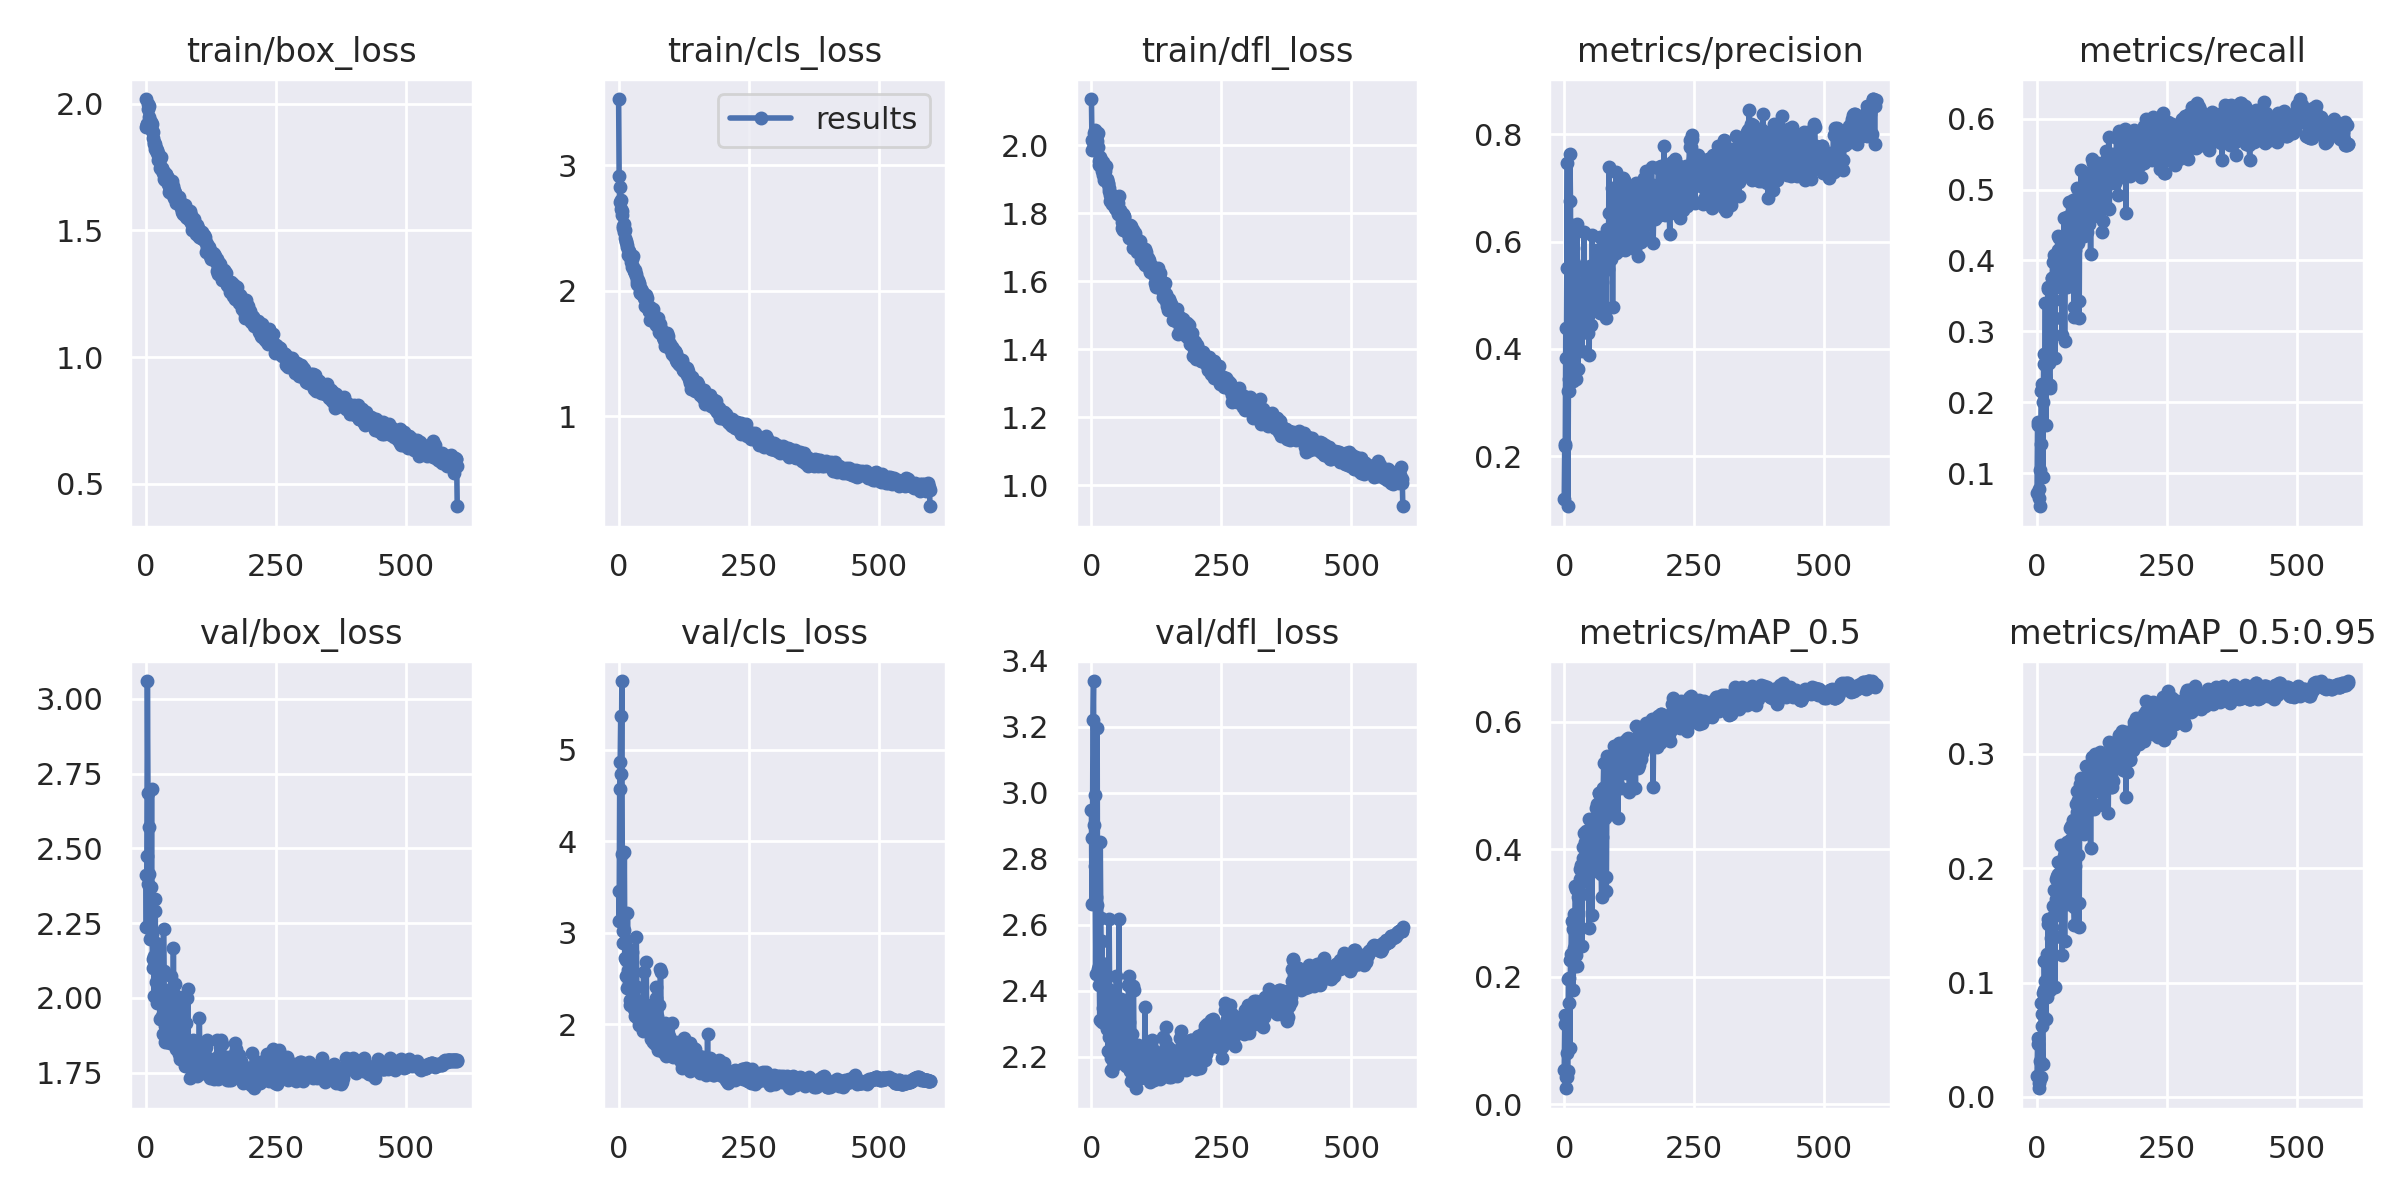

In [ ]:
from IPython.display import Image

Image(filename=f"{HOME}/yolov9/runs/train/exp/results.png", width=1000)

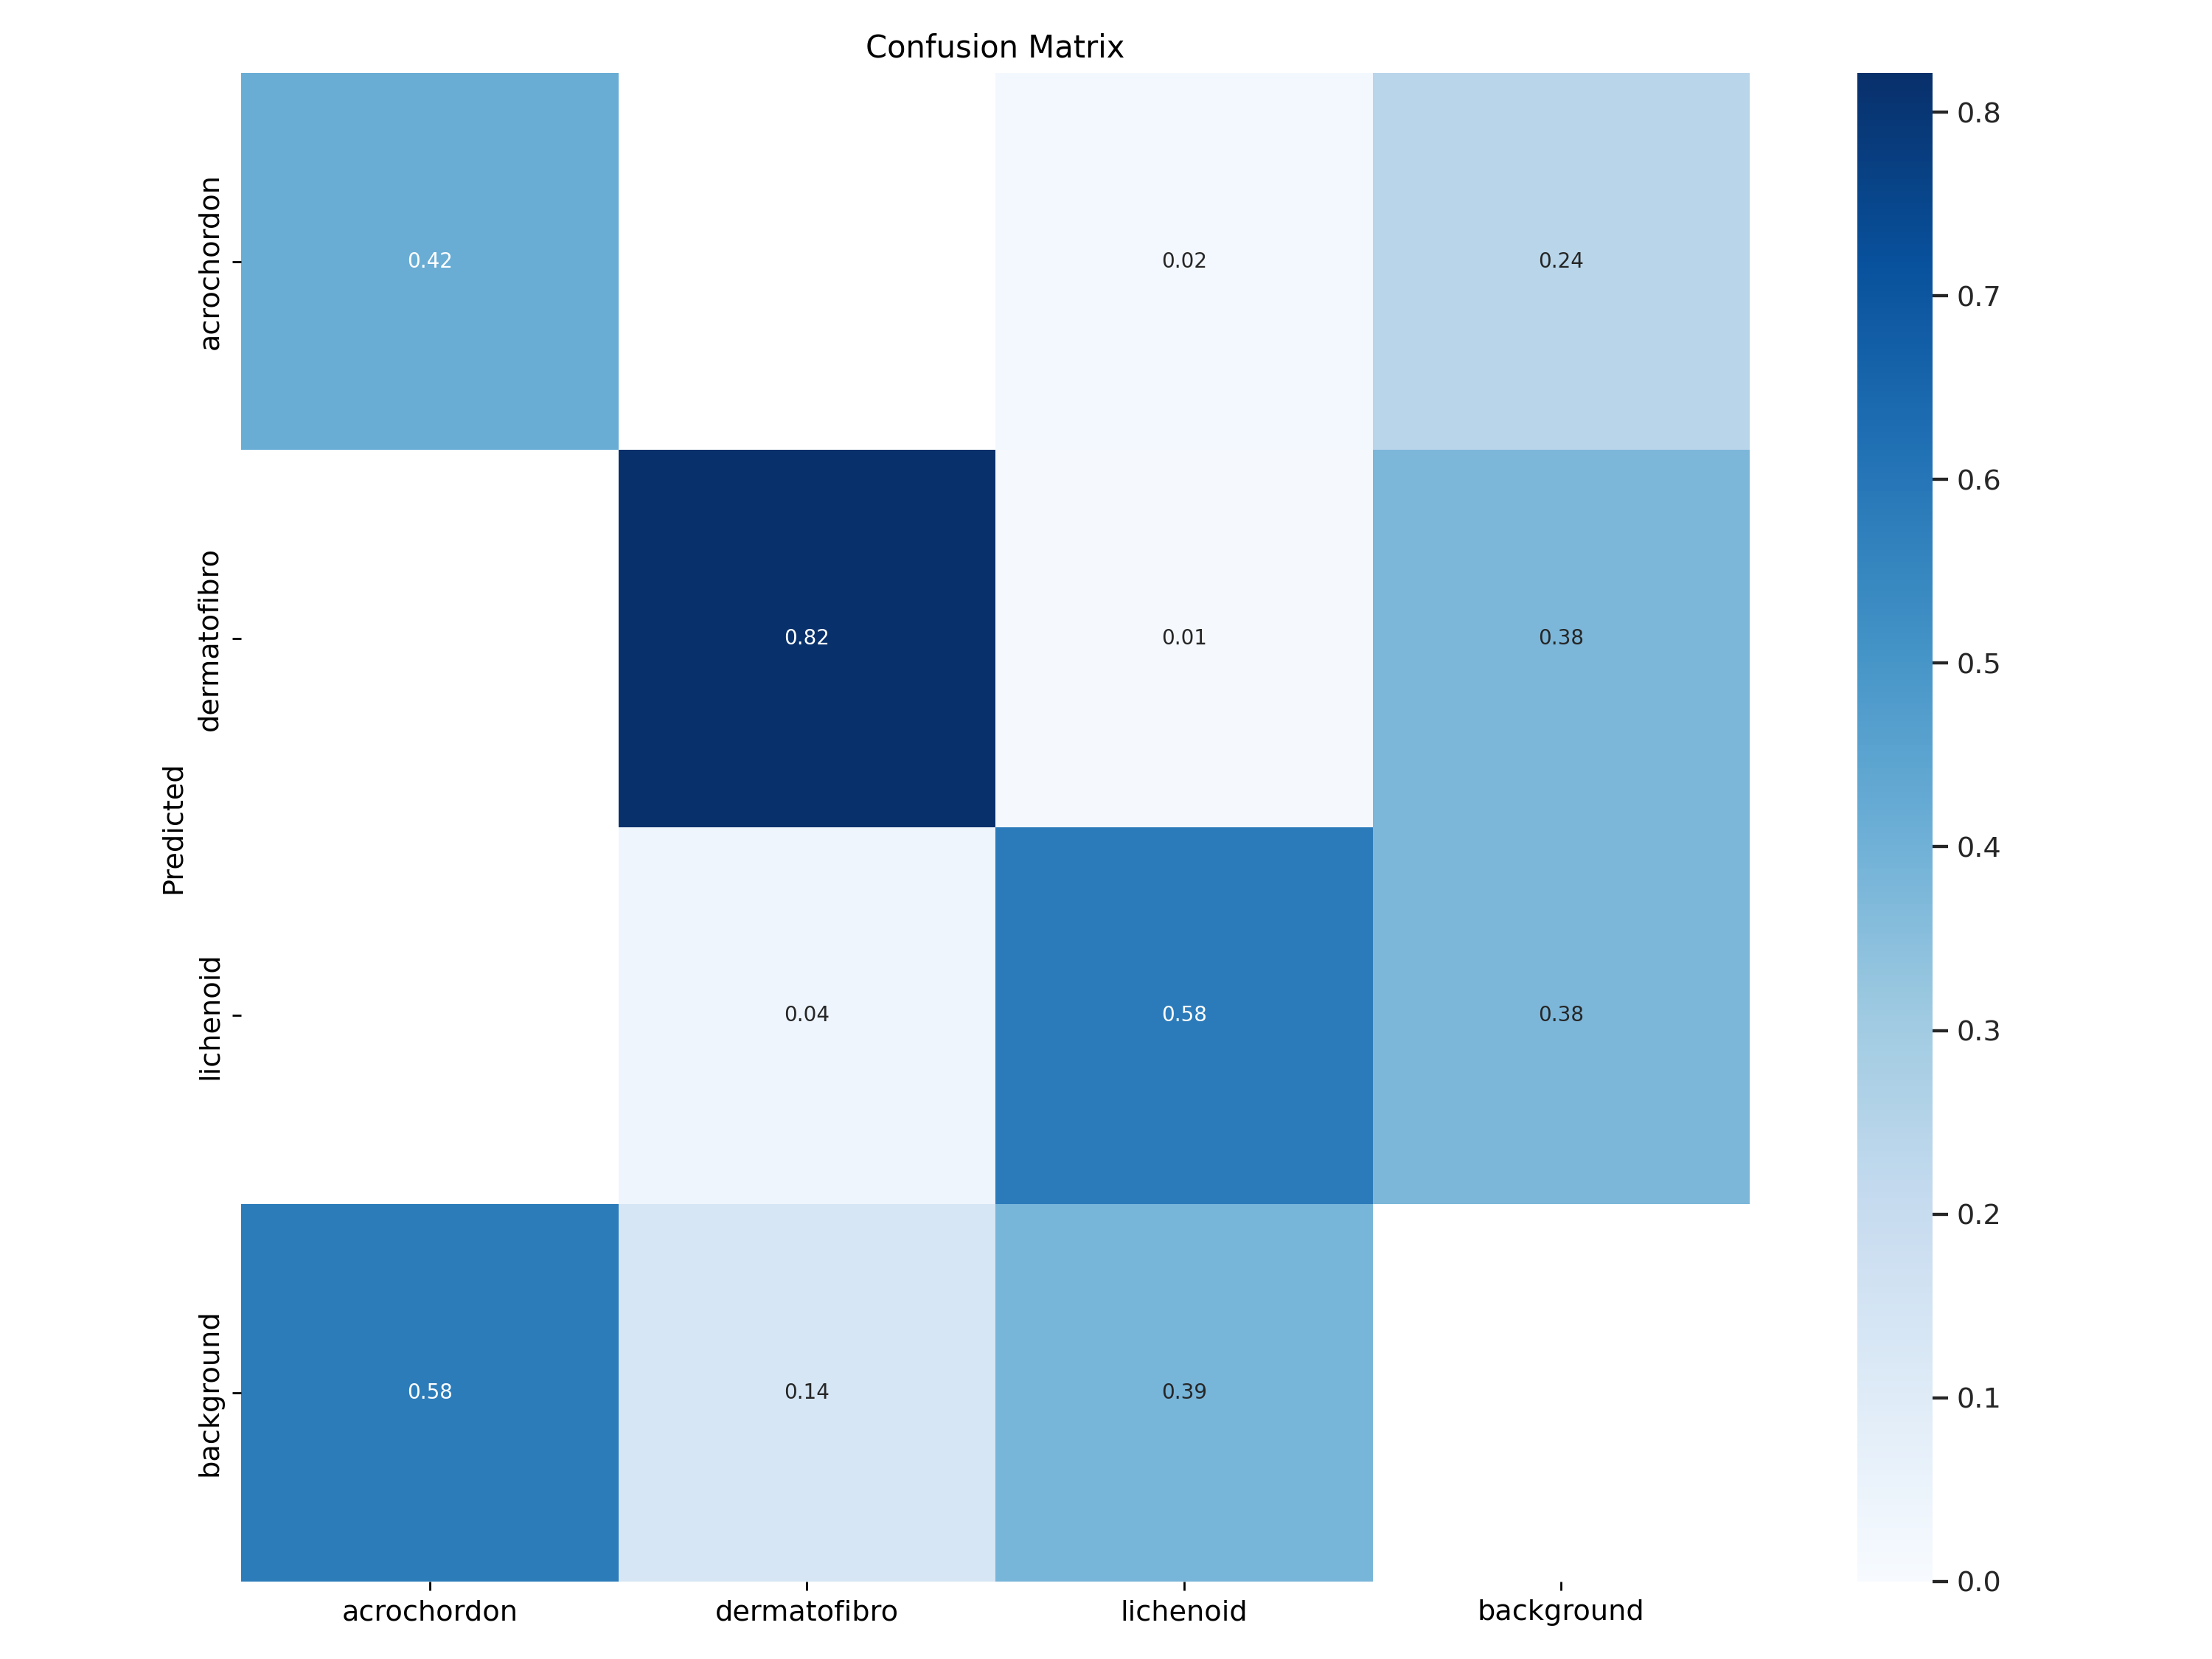

In [ ]:
from IPython.display import Image

Image(filename=f"{HOME}/yolov9/runs/train/exp/confusion_matrix.png", width=1000)

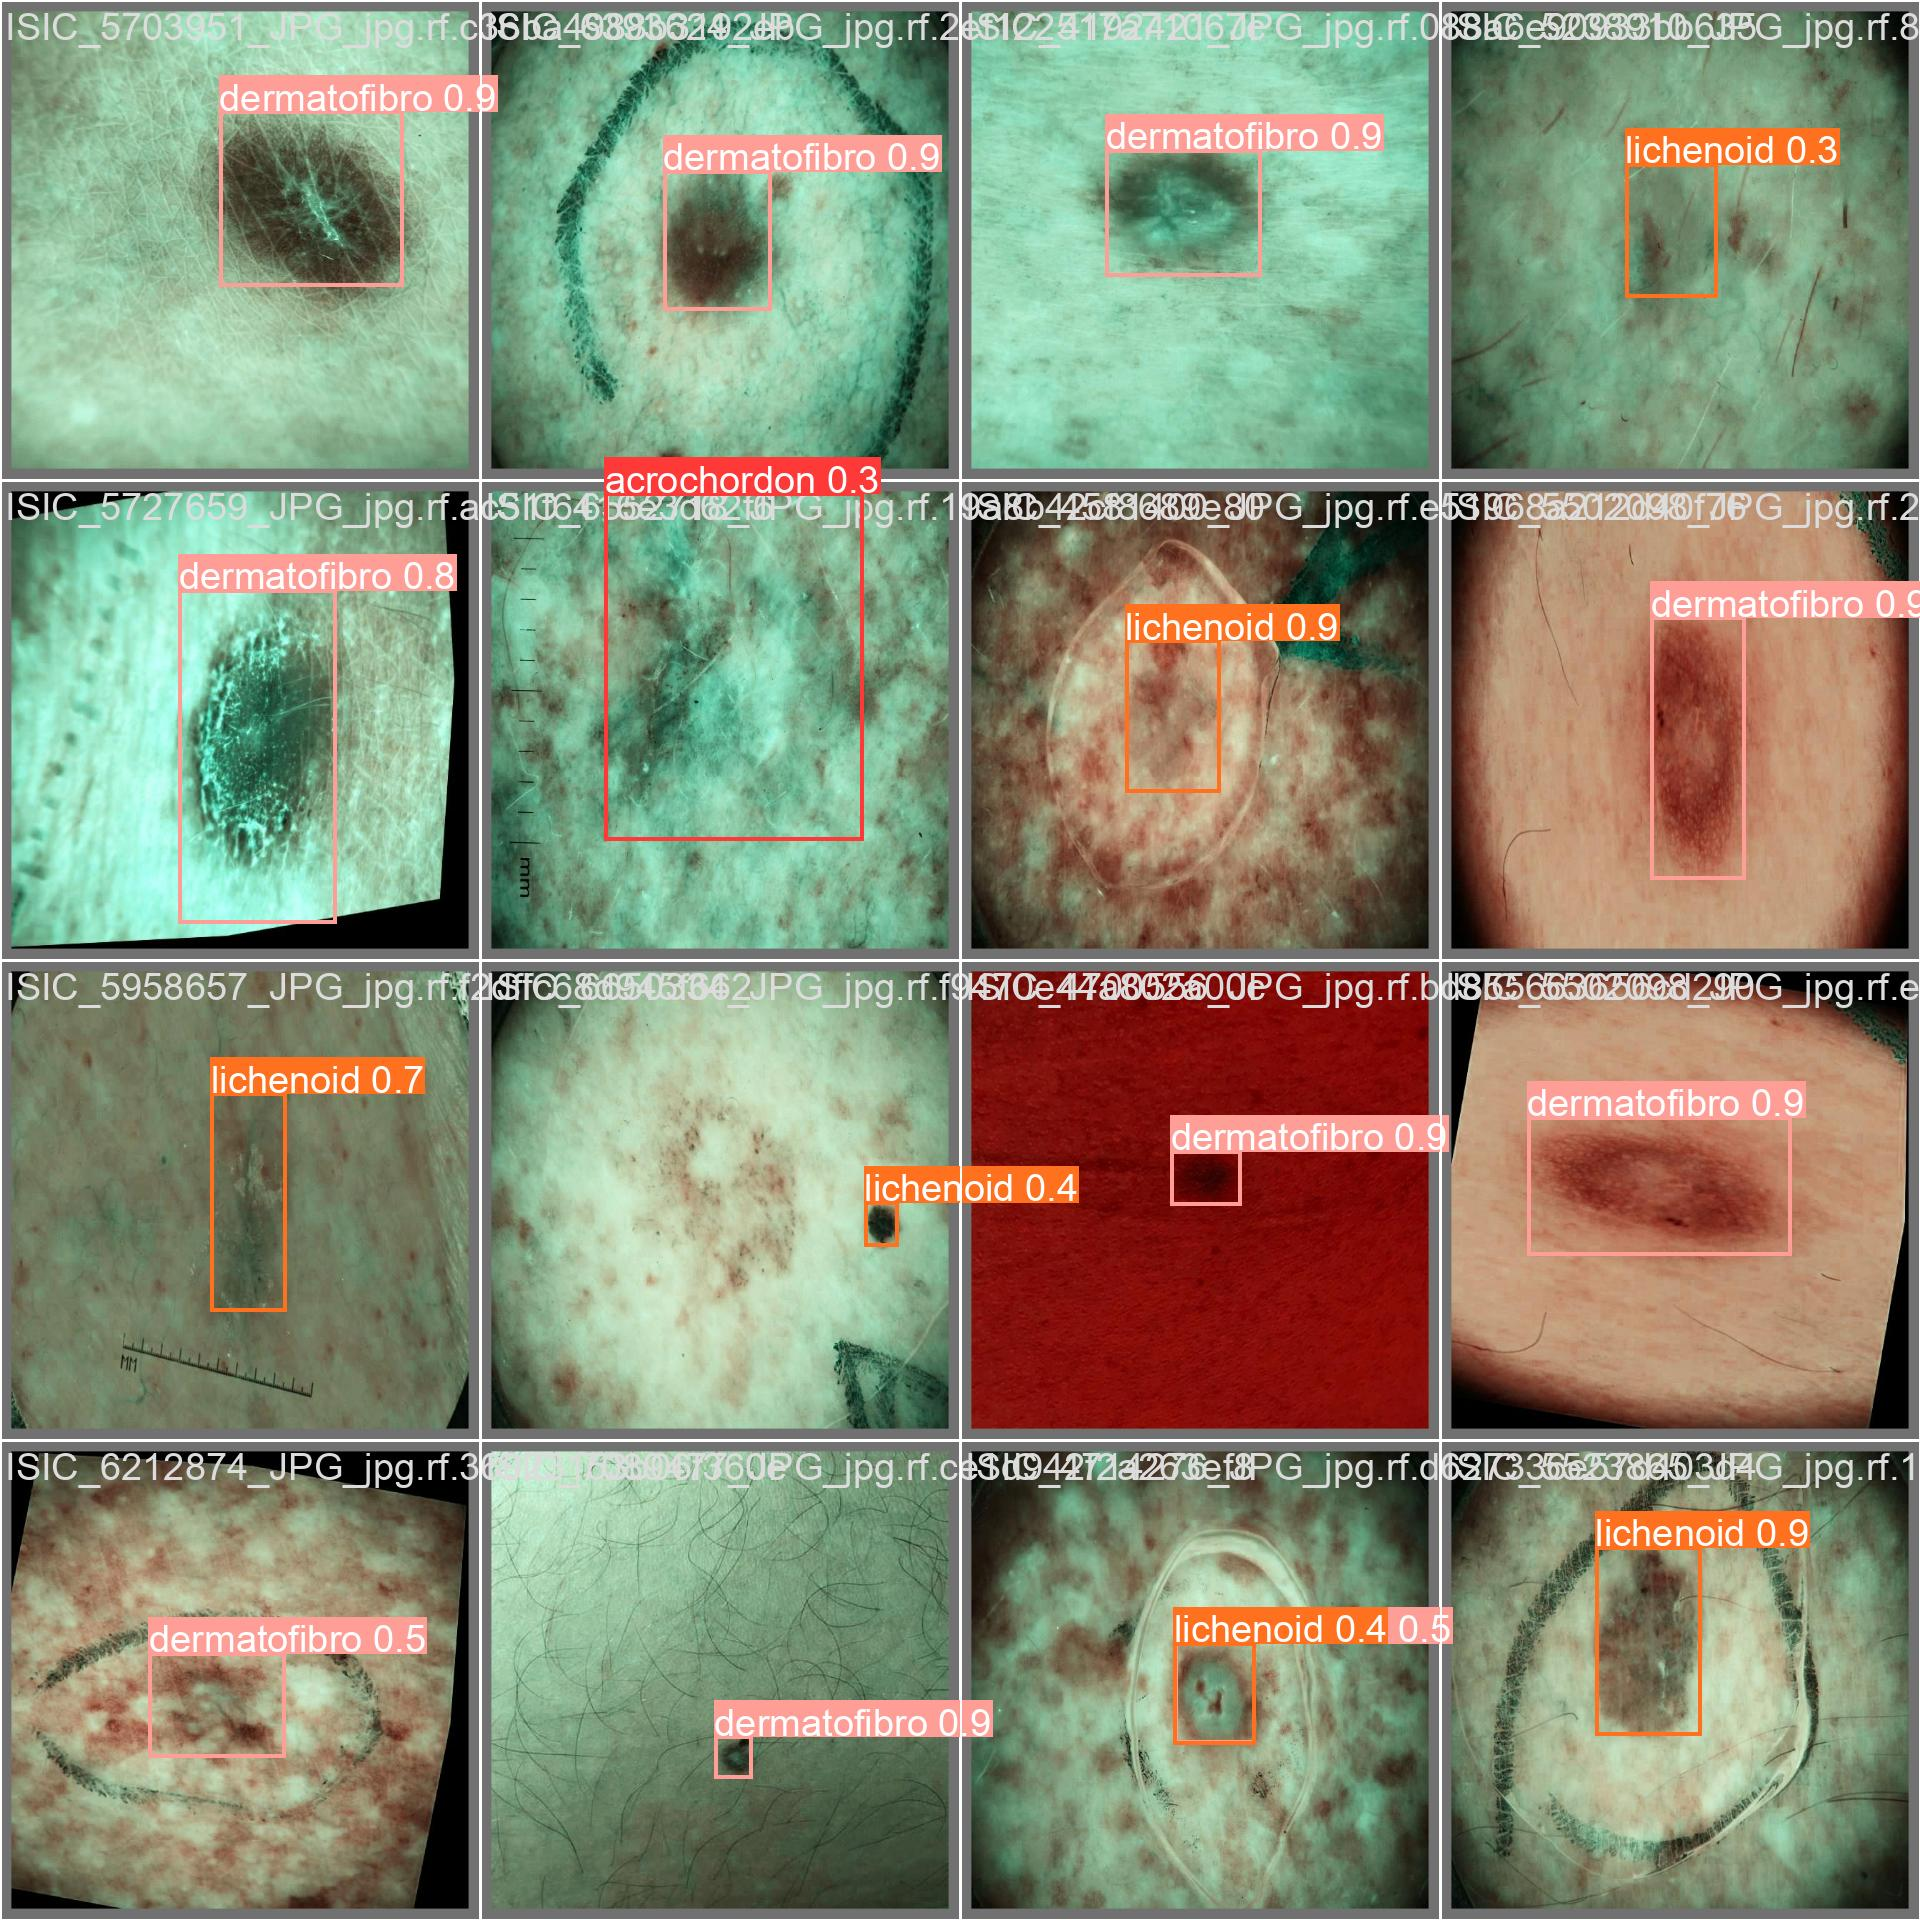

In [ ]:
from IPython.display import Image

Image(filename=f"{HOME}/yolov9/runs/train/exp/val_batch0_pred.jpg", width=1000)

## Validate Custom Model

In [ ]:
%cd {HOME}/yolov9

!python val.py \
--img 640 --batch 32 --conf 0.001 --iou 0.7 --device 0 \
--data {dataset.location}/data.yaml \
--weights {HOME}/yolov9/runs/train/exp/weights/best.pt

/content/yolov9
val: data=/content/yolov9/SC_SAVE-2/data.yaml, weights=['/content/yolov9/runs/train/exp/weights/best.pt'], batch_size=32, imgsz=640, conf_thres=0.001, iou_thres=0.7, max_det=300, task=val, device=0, workers=8, single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=runs/val, name=exp, exist_ok=False, half=False, dnn=False, min_items=0
YOLOv5 🚀 1e33dbb Python-3.10.12 torch-2.4.0+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40514MiB)

/content/yolov9/models/experimental.py:75: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits 

In [9]:
%cd {HOME}/yolov9

!python val.py \
--img 640 --batch 32 --conf 0.001 --iou 0.7 --device 0 \
--data {dataset.location}/data.yaml \
--weights /content/best.pt

/content/yolov9
val: data=/content/yolov9/SC_SAVE-2/data.yaml, weights=['/content/best.pt'], batch_size=32, imgsz=640, conf_thres=0.001, iou_thres=0.7, max_det=300, task=val, device=0, workers=8, single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=runs/val, name=exp, exist_ok=False, half=False, dnn=False, min_items=0
YOLOv5 🚀 1e33dbb Python-3.10.12 torch-2.4.0+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40514MiB)

/content/yolov9/models/experimental.py:75: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be ex

In [10]:
!zip -r /content/yolov9/runs/valV9SAVE.zip /content/yolov9/runs/val
from google.colab import files
files.download("/content/yolov9/runs/valV9SAVE.zip")

  adding: content/yolov9/runs/val/ (stored 0%)
  adding: content/yolov9/runs/val/exp/ (stored 0%)
  adding: content/yolov9/runs/val/exp/PR_curve.png (deflated 13%)
  adding: content/yolov9/runs/val/exp/confusion_matrix.png (deflated 26%)
  adding: content/yolov9/runs/val/exp/R_curve.png (deflated 13%)
  adding: content/yolov9/runs/val/exp/P_curve.png (deflated 11%)
  adding: content/yolov9/runs/val/exp/F1_curve.png (deflated 11%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print(dataset.class_to_idx)  # Check the class mapping


{'test': 0, 'train': 1, 'valid': 2}


In [ ]:
!git clone https://github.com/ultralytics/yolov9
!cd yolov9
!pip install -r requirements.txt

Cloning into 'yolov9'...
fatal: could not read Username for 'https://github.com': No such device or address
/bin/bash: line 1: cd: yolov9: No such file or directory


In [ ]:
# Example command to run YOLOv9 inference on your dataset
!python detect.py --weights /content/yolov9/runs/train/exp/weights/best.pt --img 640 --conf 0.25 --source /content/yolov9/SC_SAVE-2/test/images --save-txt --save-conf


detect: weights=['/content/yolov9/runs/train/exp/weights/best.pt'], source=/content/yolov9/SC_SAVE-2/test/images, data=data/coco128.yaml, imgsz=[640, 640], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=True, save_conf=True, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, visualize=False, update=False, project=runs/detect, name=exp, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 1e33dbb Python-3.10.12 torch-2.4.0+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40514MiB)

/content/yolov9/models/experimental.py:75: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future 

Mismatched lengths for ISIC_0012087_JPG_jpg.rf.89564ffc0776ef2028381e078435b67a.txt: Ground truth - 2, Predictions - 1
Mismatched lengths for ISIC_0023944_JPG_jpg.rf.b8b03702a40be070ef84c67dbb0314ad.txt: Ground truth - 3, Predictions - 4
Mismatched lengths for ISIC_0021217_JPG_jpg.rf.f3dbbaa2ba3de89848194caffde06e4d.txt: Ground truth - 7, Predictions - 1
No prediction file found for ISIC_0022664_JPG_jpg.rf.7b0d826d9502109e92b87df4d51134ef.txt
Mismatched lengths for ISIC_0024168_JPG_jpg.rf.0e2e6df6c0df5c31be555bd363037a22.txt: Ground truth - 3, Predictions - 2
Mismatched lengths for ISIC_0022690_JPG_jpg.rf.8cb0ad616ced971ee0f81882d6665e6c.txt: Ground truth - 2, Predictions - 1
Mismatched lengths for ISIC_0023420_JPG_jpg.rf.60f4a43b640f22f0a37aad60c9e9588e.txt: Ground truth - 2, Predictions - 1
No prediction file found for ISIC_0021629_JPG_jpg.rf.bb12b411fc01e6013723a45b8e435aff.txt
Mismatched lengths for ISIC_0013259_JPG_jpg.rf.f4d82b77e4eb39c48244529bd15b2734.txt: Ground truth - 4, Pre

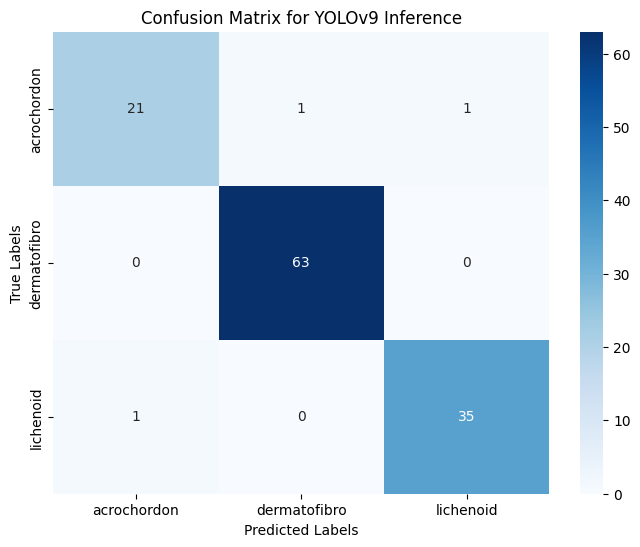

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Path to ground truth and predictions (adjust paths)
ground_truth_path = '/content/yolov9/SC_SAVE-2/test/labels'
predictions_path = '/content/yolov9/runs/detect/exp3/labels'

class_names = ['acrochordon', 'dermatofibro', 'lichenoid']  # Your 3 classes

# Initialize lists to store labels
ground_truth_labels = []
predicted_labels = []

# Function to read labels from txt files
def read_labels(file_path):
    labels = []
    with open(file_path, 'r') as f:
        for line in f:
            label = int(line.split()[0])  # Class ID is the first element
            labels.append(label)
    return labels

# Loop through ground truth files
for filename in os.listdir(ground_truth_path):
    if filename.endswith('.txt'):
        # Read ground truth labels
        gt_labels = read_labels(os.path.join(ground_truth_path, filename))

        # Read predicted labels (if available)
        pred_file = os.path.join(predictions_path, filename)
        if os.path.exists(pred_file):
            pred_labels = read_labels(pred_file)
            # Ensure both lists have the same length for comparison
            if len(gt_labels) == len(pred_labels):
                ground_truth_labels.extend(gt_labels)
                predicted_labels.extend(pred_labels)
            else:
                # Handle cases with mismatched lengths (e.g., add -1 or skip)
                print(f"Mismatched lengths for {filename}: Ground truth - {len(gt_labels)}, Predictions - {len(pred_labels)}")
                #Instead of adding -1 to predicted labels, skip the file
                continue

        else:
            print(f"No prediction file found for {filename}")
            #Instead of adding -1 to predicted labels, skip the file
            continue

# Compute the confusion matrix
cm = confusion_matrix(ground_truth_labels, predicted_labels, labels=[0, 1, 2])

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix for YOLOv9 Inference')
plt.show()

In [ ]:
# Function to calculate precision and recall using True Positives, False Positives, and False Negatives
def calculate_precision_recall(TP, FP, FN):
    # Precision calculation
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    # Recall calculation
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0

    return precision, recall

# Values for each class
classes = {
    "Acrochordon": {"TP": 21, "FP": 2, "FN": 2},
    "Dermatofibro": {"TP": 63, "FP": 0, "FN": 1},
    "Lichenoid": {"TP": 35, "FP": 1, "FN": 1}
}

# Calculate and print precision and recall for each class
for class_name, values in classes.items():
    precision, recall = calculate_precision_recall(values['TP'], values['FP'], values['FN'])
    print(f"{class_name}: Precision = {precision:.2f}, Recall = {recall:.2f}")


Acrochordon: Precision = 0.91, Recall = 0.91
Dermatofibro: Precision = 1.00, Recall = 0.98
Lichenoid: Precision = 0.97, Recall = 0.97


## Inference with Custom Model

In [ ]:
!python detect.py \
--img 1280 --conf 0.1 --device 0 \
--weights /content/yolov9/runs/train/exp/weights/best.pt \
--source /content/yolov9/SC_SAVE-2/test/images




detect: weights=['/content/yolov9/runs/train/exp/weights/best.pt'], source=/content/yolov9/SC_SAVE-2/test/images, data=data/coco128.yaml, imgsz=[1280, 1280], conf_thres=0.1, iou_thres=0.45, max_det=1000, device=0, view_img=False, save_txt=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, visualize=False, update=False, project=runs/detect, name=exp, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 1e33dbb Python-3.10.12 torch-2.4.0+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40514MiB)

/content/yolov9/models/experimental.py:75: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a fut

In [ ]:
!python val.py --weights /content/best.pt --data /content/yolov9/SC_SAVE-2/data.yaml --task test --img 640 --conf 0.25


**NOTE:** Just like behore, the inference results have been saved in the appropriate directory inside `{HOME}/yolov9/runs/detect/`. Let's examine few of those results.

In [ ]:

!zip -r /content/yolov9/runsSAVEV9.zip /content/yolov9/runs
from google.colab import files
files.download("/content/yolov9/runsSAVEV9.zip")

  adding: content/yolov9/runs/ (stored 0%)
  adding: content/yolov9/runs/detect/ (stored 0%)
  adding: content/yolov9/runs/detect/exp/ (stored 0%)
  adding: content/yolov9/runs/detect/exp/ISIC_0022510_JPG_jpg.rf.18aa418f5b25de0b6504f6dbe7667803.jpg (deflated 4%)
  adding: content/yolov9/runs/detect/exp/ISIC_0022427_JPG_jpg.rf.5171ff0b761f08ebfbf38ea209d4a6f8.jpg (deflated 7%)
  adding: content/yolov9/runs/detect/exp/ISIC_8894889_JPG_jpg.rf.852975918751187f795698bf4463790b.jpg (deflated 4%)
  adding: content/yolov9/runs/detect/exp/ISIC_0022062_JPG_jpg.rf.77cee57e7e7e3e92dd9271a5ed1cb43c.jpg (deflated 4%)
  adding: content/yolov9/runs/detect/exp/ISIC_0033860_JPG_jpg.rf.caf3c626502e22b46b1257d50ffc1aff.jpg (deflated 4%)
  adding: content/yolov9/runs/detect/exp/ISIC_0021203_JPG_jpg.rf.dc86621e6aaa030ccbb45cc33bbb4eee.jpg (deflated 6%)
  adding: content/yolov9/runs/detect/exp/ISIC_0029177_JPG_jpg.rf.e1b494356f16d412043cfd1af8525730.jpg (deflated 5%)
  adding: content/yolov9/runs/detect/exp/

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

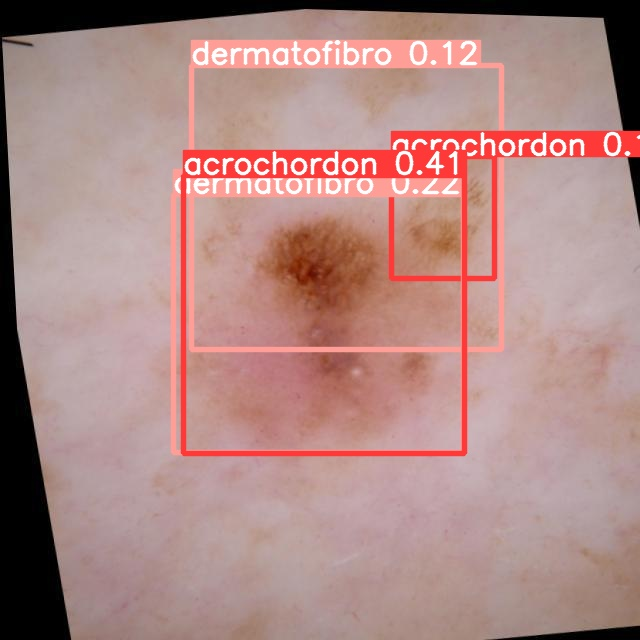

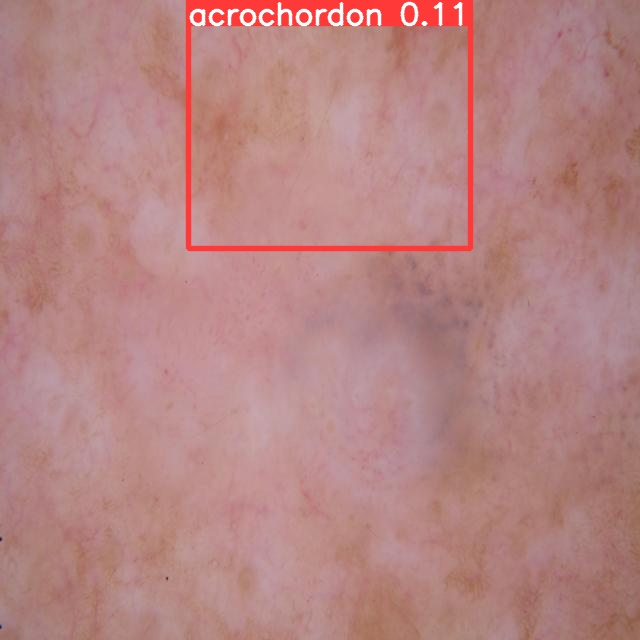

In [ ]:
import glob

from IPython.display import Image, display

for image_path in glob.glob(f'{HOME}/yolov9/runs/detect/exp2/*.jpg')[:2]:
      display(Image(filename=image_path, width=600))

## BONUS: Deploy YOLOv9 Model with Inference

**NOTE:** To deploy the model and display inference results, we will need two additional packages - [`inference`](https://pypi.org/project/inference) and [`supervision`](https://pypi.org/project/supervision). Let's install and import them!

In [ ]:
!pip install -q inference supervision

In [ ]:
import cv2
import random
import getpass

import supervision as sv

from inference import get_model

%matplotlib inline

In [ ]:
version.deploy(model_type="yolov9", model_path=f"{HOME}/yolov9/runs/train/exp")